# Описание лабораторной.

Задача бинарной классификации, необходимо реализовать следующий пайплайн:
1.	Первичный анализ (посмотреть кол-во объектов в выборке, кол-во признаков их тип, проверить баланс классов, посмотреть процент пропущенных значений в каждом признаке, посмотреть выбросы, проверить выборку на наличие дубликатов)
2.	Предобработка данных (устранение выбросов, дубликатов, заполнение пропущенных значений)
3.	Разбиение на обучающую/контрольную выборки, стандартизация
4.	Обучить модель логистической регрессии
5.	Оценить качество модели


Разбалловка:
*   **Воспроизводимость и читабельность кода - 3 балла** (все воспроизвелось и все понятно для проверяющего - 3 балла; есть непонятные моменты, но все воспроизвелось - 2 балла; непонятный код и/или воспроизводится с небольшой правкой - 1 балл; непонятный код и/или ничего не воспроизвелось - 0 баллов).
*   **Выполнение задания - (7 / (кол-во невыполненных пунктов + 1)) баллов**.


# 1. Информация о сабмите

**Охлопков Айсен Иванович**

# 2. Code

## 2.1 Первичный анализ (посмотреть кол-во объектов в выборке, кол-во признаков их тип, проверить баланс классов, посмотреть процент пропущенных значений в каждом признаке, посмотреть выбросы, проверить выборку на наличие дубликатов)
**Используйте pandas**

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
!gdown --id 1TlSSbvuDrD6tS6oemEd6Cl6N2nts-uVa

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1TlSSbvuDrD6tS6oemEd6Cl6N2nts-uVa
From (redirected): https://drive.google.com/uc?id=1TlSSbvuDrD6tS6oemEd6Cl6N2nts-uVa&confirm=t&uuid=7872c979-c2cb-47ac-8265-bfe49039ba85
To: /content/data.csv
100% 140M/140M [00:01<00:00, 78.6MB/s]


In [ ]:
df = pd.read_csv('data.csv')

In [ ]:
# Ответ(целевая переменная) - target, остальные колонки - признаки (все признаки, которые не являются числовыми, можно удалить)
df.head(5)

,reco_id_curr,target,contract_type_name,gender,own_car_flag,own_realty_flag,children_count,income,loan_body,annuity_payment,...,document_18_flag,document_19_flag,document_20_flag,document_21_flag,requests_bki_hour,requests_bki_day,requests_bki_week,requests_bki_month,requests_bki_qrt,requests_bki_year
0,384575,0,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
1,214010,0,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
2,142232,0,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
3,389171,0,Cash loans,F,N,Y,0,247500.0,254700.0,24939.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,283617,0,Cash loans,M,N,Y,0,112500.0,308133.0,15862.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,4.0


In [ ]:
# Пример нахождения всех признаков не являющихся числовыми
for i in df.columns:
    if df[i].dtype.name not in ['float64', 'int64']:
        print(i)

contract_type_name
gender
own_car_flag
own_realty_flag
type_suite_name
income_type_name
education_type_name
family_status_name
housing_type_name
type_of_occupation
start_weekday_appr_process
type_of_organization
fondkapremon_mode
mode_house_type
mode_walls_material
emergency_state_mode


In [ ]:
print(df.shape[0])
print('обьектов:', df.shape[1])

261384
обьектов: 122


In [ ]:
print('Типы обьектов')
print(df.dtypes)

Типы обьектов
reco_id_curr            int64
target                  int64
contract_type_name     object
gender                 object
own_car_flag           object
                       ...   
requests_bki_day      float64
requests_bki_week     float64
requests_bki_month    float64
requests_bki_qrt      float64
requests_bki_year     float64
Length: 122, dtype: object


In [ ]:
class_distribution = df['target'].value_counts(normalize = True)
print("Распределение классов:")
print(class_distribution)

Распределение классов:
target
0    0.919238
1    0.080762
Name: proportion, dtype: float64


In [ ]:
missing = df.isnull().mean() * 100
print("Процент пропущенных значений в каждом признаке:")
print(missing)

Процент пропущенных значений в каждом признаке:
reco_id_curr           0.000000
target                 0.000000
contract_type_name     0.000000
gender                 0.000000
own_car_flag           0.000000
                        ...    
requests_bki_day      13.479785
requests_bki_week     13.479785
requests_bki_month    13.479785
requests_bki_qrt      13.479785
requests_bki_year     13.479785
Length: 122, dtype: float64


In [ ]:
df = df.select_dtypes(include=[np.number])

In [ ]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()
print("\nКоличество выбросов в каждом признаке:")
print(outliers[outliers > 0])


Количество выбросов в каждом признаке:
target                21110
children_count         3660
income                11942
loan_body              5547
annuity_payment        6362
                      ...  
requests_bki_day       1266
requests_bki_week      7266
requests_bki_month    37187
requests_bki_qrt      42941
requests_bki_year      2843
Length: 98, dtype: int64


In [ ]:
duplicates = df.duplicated().sum()
print(duplicates)

0


## 2.2 Предобработка данных (устранение выбросов, дубликатов, заполнение пропущенных значений)
**Используйте pandas**

**пропущенные значения можно заполнить: средним, медианой, модой, нулями и т.д. (можете поэкспериментировать)**

In [ ]:
import matplotlib.pyplot as plt

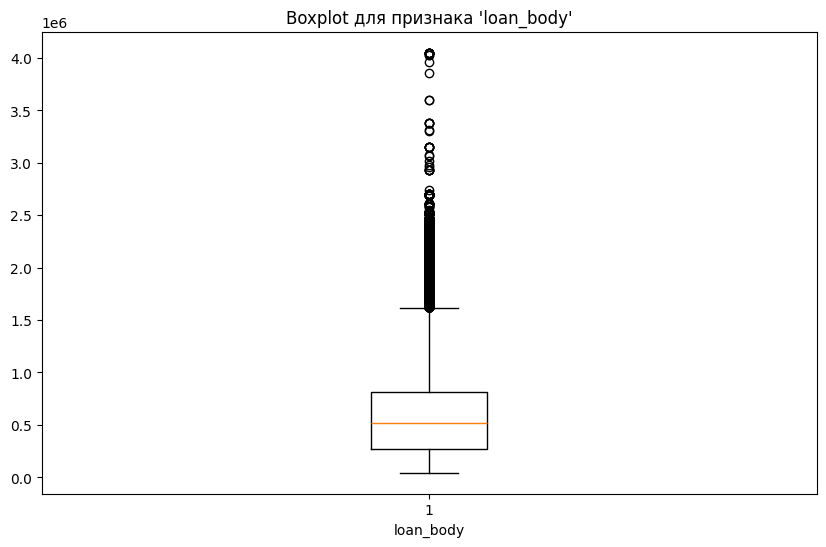

In [ ]:
plt.figure(figsize=(10, 6))
plt.boxplot(df['loan_body'], vert=True)
plt.title("Boxplot для признака 'loan_body'")
plt.xlabel('loan_body')
plt.show()

In [ ]:
mean_value = df['loan_body'].mean()
std_dev = df['loan_body'].std()

In [ ]:
lower_bound = mean_value - 5 * std_dev
upper_bound = mean_value + 5 * std_dev

In [ ]:
df_cleaned = df[(df['loan_body'] >= lower_bound) & (df['loan_body'] <= upper_bound)]

In [ ]:
print(f"Размер выборки до удаления выбросов: {df.shape}")
print(f"Размер выборки после удаления выбросов: {df_cleaned.shape}")

Размер выборки до удаления выбросов: (261384, 106)
Размер выборки после удаления выбросов: (261281, 106)


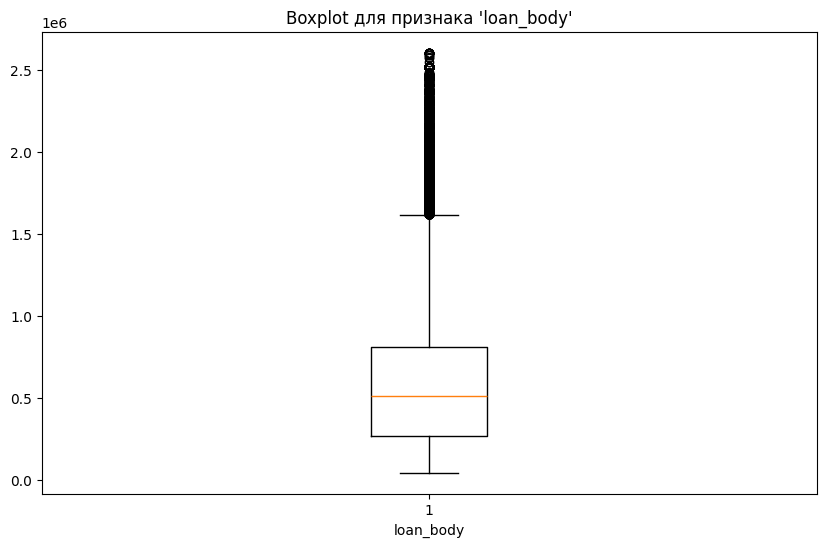

In [ ]:
plt.figure(figsize=(10, 6))
plt.boxplot(df_cleaned['loan_body'], vert=True)
plt.title("Boxplot для признака 'loan_body'")
plt.xlabel('loan_body')
plt.show()

## 2.3 Разбиение на обучающую/контрольную выборки, стандартизация
**Используйте train_test_split из sklearn**

**Для стандартизации используйте sklearn.preprocessing StandartScaler**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
X = df_final.drop(columns=['target'], axis=1)
y = df_final['target']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("Размер обучающей выборки X_train:", X_train.shape)
print("Размер контрольной выборки X_test:", X_test.shape)
print("Размер обучающей выборки y_train:", y_train.shape)
print("Размер контрольной выборки y_test:", y_test.shape)

Размер обучающей выборки X_train: (209107, 105)
Размер контрольной выборки X_test: (52277, 105)
Размер обучающей выборки y_train: (209107,)
Размер контрольной выборки y_test: (52277,)


In [ ]:
print("Обучающая выборка (признаки) после стандартизации:")
print(X_train_scaled)

print("\nКонтрольная выборка (признаки) после стандартизации:")
print(X_test_scaled)

Обучающая выборка (признаки) после стандартизации:
[[ 1.06273899 -0.57734351 -0.17072558 ... -0.26958116 -0.28317833
   0.19191542]
 [ 0.37777909 -0.57734351 -0.28339204 ... -0.26958116  0.95269861
   1.26909486]
 [ 0.83191169 -0.57734351  0.03851213 ...  0.89068039 -0.28317833
  -0.88526402]
 ...
 [ 0.15374397 -0.57734351 -0.04196391 ... -0.26958116 -0.28317833
  -0.3466743 ]
 [-1.28807764  0.80415703 -0.21901121 ... -0.26958116 -0.28317833
  -0.88526402]
 [ 1.02949814 -0.57734351 -0.28339204 ... -0.26958116  0.95269861
  -0.88526402]]

Контрольная выборка (признаки) после стандартизации:
[[-0.63492814 -0.57734351  0.76279652 ...  0.89068039 -0.28317833
  -0.3466743 ]
 [-0.52164069 -0.57734351  0.19946422 ... -0.26958116 -0.28317833
  -0.88526402]
 [-0.52180612 -0.57734351 -0.31558246 ... -0.26958116 -0.28317833
  -0.88526402]
 ...
 [-0.52314899 -0.57734351  0.3604163  ... -0.26958116 -0.28317833
  -0.3466743 ]
 [ 0.50261714 -0.57734351 -0.23510642 ... -0.26958116 -0.28317833
  -0.346

## 2.4 Обучить модель логистической регрессии
**Используйте LogisticRegression из sklearn.linear_model**


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
print(y.value_counts())

target
0    240274
1     21110
Name: count, dtype: int64


In [ ]:
model = LogisticRegression(max_iter=100,  class_weight='balanced')
model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(class_weight='balanced')

In [ ]:
y_pred = model.predict(X_test_scaled)
print(y_pred)

[1 1 1 ... 0 0 1]


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 2.5 Оценить качество модели
**Используйте accuracy_score, precision_score, recall_score и f1_score из sklearn.metrics**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [ ]:
print(f"Точность модели: {accuracy:.2f}")
print(f"Точность (Precision): {precision:.2f}")
print(f"Полнота (Recall): {recall:.2f}")
print(f"F1-мера: {f1:.2f}")


Точность модели: 0.48
Точность (Precision): 0.10
Полнота (Recall): 0.65
F1-мера: 0.17


# 3. Обратная связь
**Опишите здесь что было не понятно/вызвало наибольшие трудности в задании, о чем стоит рассказать подробнее на занятиях**


сложности появились когда Обучить модель логистической регрессии. Была ошибка где у меня в классе показывала 0.0 элементов. Не смог исправить начал делать заново исправилось само по себе.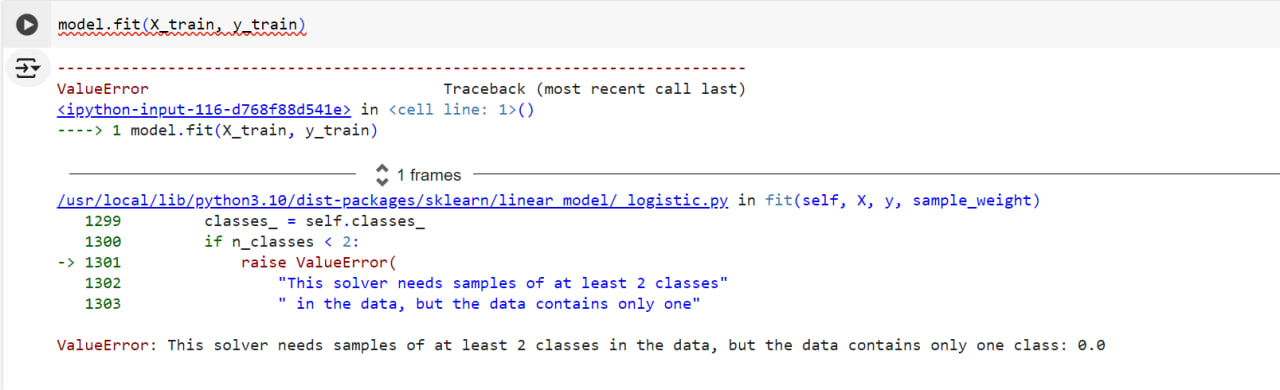